In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (make_scorer, r2_score,
                             mean_squared_error, mean_absolute_error)

df = pd.read_csv('/content/mangrove_komodo_multi_band_glcm.csv')
df = df.dropna()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6916 entries, 0 to 6915
Data columns (total 68 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   system:index   6916 non-null   int64  
 1   AGC            6916 non-null   float64
 2   B11            6916 non-null   float64
 3   B11_asm        6916 non-null   float64
 4   B11_contrast   6916 non-null   float64
 5   B11_corr       6916 non-null   float64
 6   B11_ent        6916 non-null   float64
 7   B12            6916 non-null   float64
 8   B12_asm        6916 non-null   float64
 9   B12_contrast   6916 non-null   float64
 10  B12_corr       6916 non-null   float64
 11  B12_ent        6916 non-null   float64
 12  B2             6916 non-null   float64
 13  B2_asm         6916 non-null   float64
 14  B2_contrast    6916 non-null   float64
 15  B2_corr        6916 non-null   float64
 16  B2_ent         6916 non-null   float64
 17  B3             6916 non-null   float64
 18  B3_asm       

In [ ]:
df.describe()

,system:index,AGC,B11,B11_asm,B11_contrast,B11_corr,B11_ent,B12,B12_asm,B12_contrast,...,NDRE,NDVI,RH25,RH50,RH75,RH95,SAVI,canopy_height,canopy_ratio,random
count,10139.000000,10139.000000,10139.000000,10139.000000,1.013900e+04,10139.000000,10139.000000,10139.000000,10139.000000,1.013900e+04,...,10139.000000,10139.000000,10139.000000,10139.000000,10139.000000,10139.000000,10139.000000,10139.000000,10139.000000,10139.000000
mean,5069.000000,15.244933,2400.073183,0.012974,1.527964e+13,0.537422,4.349244,1326.704507,0.012995,7.889913e+12,...,0.387084,0.617690,-0.747708,1.255257,3.416583,6.564029,0.926383,7.311737,0.421415,0.497074
std,2927.021524,19.160351,713.671702,0.000595,1.294544e+13,0.162048,0.034873,494.493654,0.000613,6.159375e+12,...,0.114340,0.156535,1.881094,2.362977,3.056882,4.039174,0.234756,3.288716,0.176930,0.289215
min,0.000000,0.040303,183.000000,0.012897,2.224352e+11,-0.030261,3.686757,104.000000,0.012897,1.137618e+11,...,0.073688,0.300032,-7.550000,-2.990000,-0.410000,0.000000,0.449976,0.000000,-0.244048,0.000061
25%,2534.500000,3.838405,1902.250000,0.012897,7.032753e+12,0.426961,4.349616,937.000000,0.012897,3.889358e+12,...,0.294738,0.486948,-1.680000,0.000000,1.380000,3.680000,0.730320,5.230000,0.334302,0.245392
50%,5069.000000,8.563546,2433.000000,0.012897,1.189562e+13,0.544507,4.353741,1333.000000,0.012897,6.508468e+12,...,0.376324,0.616029,-1.120000,0.335000,2.350000,5.790000,0.923905,7.290000,0.403087,0.499267
75%,7603.500000,19.320680,2961.000000,0.012968,1.932864e+13,0.658793,4.353741,1718.000000,0.012993,1.031409e+13,...,0.477695,0.761871,-0.292500,1.490000,4.450000,8.710000,1.142579,9.300000,0.526882,0.745773
max,10138.000000,251.557173,4311.000000,0.025267,1.170938e+14,0.871531,4.353741,2772.000000,0.026388,5.575456e+13,...,0.708248,0.945763,16.980000,23.830000,28.209999,32.480000,1.418377,20.829999,0.889116,0.999843


In [ ]:
df.isna()

,system:index,AGC,B11,B11_asm,B11_contrast,B11_corr,B11_ent,B12,B12_asm,B12_contrast,...,RH25,RH50,RH75,RH95,SAVI,canopy_height,canopy_ratio,random,split,.geo
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10134,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10135,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10136,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10137,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.head()

,system:index,AGC,B11,B11_asm,B11_contrast,B11_corr,B11_ent,B12,B12_asm,B12_contrast,...,RH25,RH50,RH75,RH95,SAVI,canopy_height,canopy_ratio,random,split,.geo
0,0,3.033496,3654.0,0.019048,1.564609e+13,0.459820,3.965525,2144.0,0.019048,8.993310e+12,...,-1.49,0.0300,1.57000,4.11000,0.652072,5.60000,0.381995,0.106241,training,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
1,1,3.033496,3813.0,0.019048,1.539610e+13,0.443593,3.965525,2219.0,0.019048,8.398247e+12,...,-1.49,0.0300,1.57000,4.11000,0.548992,5.60000,0.381995,0.698900,training,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
2,2,3.033496,3951.0,0.019048,1.620199e+13,0.366947,3.965525,2345.0,0.019048,8.520815e+12,...,-1.49,0.0300,1.57000,4.11000,0.560787,5.60000,0.381995,0.144779,training,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
3,3,5.366003,3448.0,0.019048,1.405318e+13,0.573845,3.965525,2007.0,0.019048,7.485392e+12,...,-1.14,-0.0350,1.10250,3.18750,0.589091,4.32750,0.344221,0.713130,testing,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
4,4,5.366003,3346.0,0.019048,1.270270e+13,0.560782,3.965525,1900.0,0.019325,6.820380e+12,...,-0.57,-0.0175,0.55125,1.59375,0.577538,2.16375,0.172111,0.465548,training,"{""geodesic"":false,""type"":""Point"",""coordinates""..."


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (make_scorer, r2_score,
                             mean_squared_error, mean_absolute_error)

df = pd.read_csv('/content/mangrove_komodo_multi_band_glcm.csv')
df = df.dropna()

print(f"Shape: {df.shape}")
print(f"\nKolom tersedia:\n{df.columns.tolist()}")

print(f"\nAGC stats:\n{df['AGC'].describe().round(2)}")
print(f"\nRH95 stats:\n{df['RH95'].describe().round(2)}")
print(f"\nKorelasi RH95 vs AGC: {df['RH95'].corr(df['AGC']):.4f}")

target_bands = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']
target_metrics = ['contrast', 'corr', 'ent', 'asm']

glcm_columns = []
for b in target_bands:
    for m in target_metrics:
        col_name = f"{b}_{m}"
        if col_name in df.columns:
            glcm_columns.append(col_name)

feature_groups = {
    'Spectral': [c for c in df.columns if c in
        ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']],

    'VI': [c for c in df.columns if c in
        ['NDVI','EVI','SAVI','NDRE','GNDVI','DVI','IRECI']],

    'GLCM': glcm_columns,

    'LiDAR': [c for c in df.columns if c in
        ['RH25','RH50','RH75','RH95',
         'canopy_height','canopy_ratio']]
}

for k, v in feature_groups.items():
    print(f"{k}: {v}")

S = feature_groups['Spectral']
V = feature_groups['VI']
G = feature_groups['GLCM']
L = feature_groups['LiDAR']

# EXPERIMENT 1: Sentinel-2 Only

ablation_s2 = {
    'S1: Spectral': S,
    'S2: VI': V,
    'S3: GLCM': G,
    'S4: Spectral+VI': S+V,
    'S5: Spectral+GLCM': S+G,
    'S6: VI+GLCM': V+G,
    'S7: Full S2': S+V+G,
}

# EXPERIMENT 2: Sentinel-2 + LiDAR

ablation_s2_lidar = {
    'L1: Spectral': S,
    'L2: VI': V,
    'L3: GLCM': G,
    'L4: LiDAR': L,
    'L5: Spectral+VI': S+V,
    'L6: Spectral+GLCM': S+G,
    'L7: Spectral+LiDAR': S+L,
    'L8: VI+GLCM': V+G,
    'L9: VI+LiDAR': V+L,
    'L10: GLCM+LiDAR': G+L,
    'L11: Spectral+VI+GLCM': S+V+G,
    'L12: Spectral+VI+LiDAR': S+V+L,
    'L13: Spectral+GLCM+LiDAR': S+G+L,
    'L14: VI+GLCM+LiDAR': V+G+L,
    'L15: Full (S+VI+GLCM+LiDAR)': S+V+G+L,
}


def rmse_scorer(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

scorers = {
    'r2': make_scorer(r2_score),
    'rmse': make_scorer(rmse_scorer),
    'mae': make_scorer(mean_absolute_error)
}


model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)
global fold_preds
fold_preds = []

def run_ablation(df_in, configs, experiment_name):
    y = df_in['AGC'].values
    results = []


    for name, features in configs.items():

        feats = [f for f in features if f in df_in.columns]
        if len(feats) == 0:
            continue

        n_splits = min(5, max(2, len(df_in)//10))
        cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)

        X = df_in[feats].values

        out = cross_validate(
            model, X, y,
            cv=cv,
            scoring=scorers,
            return_train_score=False,
            n_jobs=-1
        )

        res = {
            'Experiment': experiment_name,
            'Configuration': name,
            'Domains': _get_domains(name),
            'N_features': len(feats),
            'R2_mean': round(out['test_r2'].mean(), 4),
            'R2_std': round(out['test_r2'].std(), 4),
            'RMSE_mean': round(out['test_rmse'].mean(), 4),
            'RMSE_std': round(out['test_rmse'].std(), 4),
            'MAE_mean': round(out['test_mae'].mean(), 4),
            'MAE_std': round(out['test_mae'].std(), 4),
        }

        results.append(res)

        print(f"  {name}: "
              f"R²={res['R2_mean']:.4f} | "
              f"RMSE={res['RMSE_mean']:.4f} | "
              f"MAE={res['MAE_mean']:.4f}")

    return results

def _get_domains(config_name):
    domains = []
    if 'Spectral' in config_name: domains.append('Spectral')
    if 'VI' in config_name: domains.append('VI')
    if 'GLCM' in config_name: domains.append('GLCM')
    if 'LiDAR' in config_name: domains.append('LiDAR')
    return '+'.join(domains)


print("EXPERIMENT 1: SENTINEL-2 ONLY")

all_results = []
all_results += run_ablation(df, ablation_s2, 'EXP1_S2only')

print("\n")
print("EXPERIMENT 2: SENTINEL-2 + LIDAR")


all_results += run_ablation(df, ablation_s2_lidar, 'EXP2_S2+LiDAR')


df_results = pd.DataFrame(all_results)
df_results.to_csv('ablation_results_final.csv', index=False)

overall1 = df_results[df_results['Experiment']=='EXP1_S2only']
overall2 = df_results[df_results['Experiment']=='EXP2_S2+LiDAR']

r2_s2_full = overall1[overall1['Configuration']=='S7: Full S2']['R2_mean'].values[0]
r2_lidar_only = overall2[overall2['Configuration']=='L4: LiDAR']['R2_mean'].values[0]
r2_full_all = overall2[overall2['Configuration']=='L15: Full (S+VI+GLCM+LiDAR)']['R2_mean'].values[0]

print("\n" + "="*60)
print("KEY COMPARISON")
print("="*60)

print(f"S2 Full       : {r2_s2_full:.4f}")
print(f"LiDAR Only    : {r2_lidar_only:.4f}")
print(f"Full Model    : {r2_full_all:.4f}")

print(f"Gap S2 vs LiDAR: {r2_lidar_only - r2_s2_full:.4f}")

lidar_replaceable = r2_lidar_only - r2_s2_full < 0.05
print(f"\nConclusion: Sentinel-2 {'CAN' if lidar_replaceable else 'CANNOT'} replace LiDAR")

Shape: (10139, 68)

Kolom tersedia:
['system:index', 'AGC', 'B11', 'B11_asm', 'B11_contrast', 'B11_corr', 'B11_ent', 'B12', 'B12_asm', 'B12_contrast', 'B12_corr', 'B12_ent', 'B2', 'B2_asm', 'B2_contrast', 'B2_corr', 'B2_ent', 'B3', 'B3_asm', 'B3_contrast', 'B3_corr', 'B3_ent', 'B4', 'B4_asm', 'B4_contrast', 'B4_corr', 'B4_ent', 'B5', 'B5_asm', 'B5_contrast', 'B5_corr', 'B5_ent', 'B6', 'B6_asm', 'B6_contrast', 'B6_corr', 'B6_ent', 'B7', 'B7_asm', 'B7_contrast', 'B7_corr', 'B7_ent', 'B8', 'B8A', 'B8A_asm', 'B8A_contrast', 'B8A_corr', 'B8A_ent', 'B8_asm', 'B8_contrast', 'B8_corr', 'B8_ent', 'DVI', 'EVI', 'GNDVI', 'IRECI', 'NDRE', 'NDVI', 'RH25', 'RH50', 'RH75', 'RH95', 'SAVI', 'canopy_height', 'canopy_ratio', 'random', 'split', '.geo']

AGC stats:
count    10139.00
mean        15.24
std         19.16
min          0.04
25%          3.84
50%          8.56
75%         19.32
max        251.56
Name: AGC, dtype: float64

RH95 stats:
count    10139.00
mean         6.56
std          4.04
min     

In [ ]:

overall_stats = df['AGC'].agg(['count', 'mean', 'std', 'min', 'median', 'max']).to_frame().T
overall_stats.index = ['Overall']

summary_list = []

for group_name, cols in feature_groups.items():
    group_df = df[cols + ['AGC']].dropna()

    stats = group_df['AGC'].agg({
        'N': 'count',
        'Mean': 'mean',
        'Std': 'std',
        'Min': 'min',
        'Median': 'median',
        'Max': 'max'
    })
    stats.name = group_name
    summary_list.append(stats)
agc_stats_by_group = pd.DataFrame(summary_list)

overall_row = pd.Series({
    'N': len(df),
    'Mean': df['AGC'].mean(),
    'Std': df['AGC'].std(),
    'Min': df['AGC'].min(),
    'Median': df['AGC'].median(),
    'Max': df['AGC'].max()
}, name='Overall Data')

agc_stats_final = pd.concat([agc_stats_by_group, overall_row.to_frame().T]).round(2)

print("\n" + "="*30)
print("TABLE 2: AGC STATS BY FEATURE DOMAIN")
print("="*30)
print(agc_stats_final)



TABLE 2: AGC STATS BY FEATURE DOMAIN
                    N   Mean    Std   Min  Median     Max
Spectral      10139.0  15.24  19.16  0.04    8.56  251.56
VI            10139.0  15.24  19.16  0.04    8.56  251.56
GLCM          10139.0  15.24  19.16  0.04    8.56  251.56
LiDAR         10139.0  15.24  19.16  0.04    8.56  251.56
Overall Data  10139.0  15.24  19.16  0.04    8.56  251.56


=== AGC Descriptive Statistics (Table II) ===
N         10139.00
Mean         15.24
Std          19.16
Min           0.04
Q25           3.84
Median        8.56
Q75          19.32
Max         251.56
CV          125.68
Name: AGC, dtype: float64
R² Sentinel-2 All Feature	: 0.3472
R² LiDAR Only			: 0.7949
R² Sentinel-2 + LiDAR		: 0.8731
Gap LiDAR vs S2			: 0.4477
S2 vs LiDAR Ratio		: 43.7%


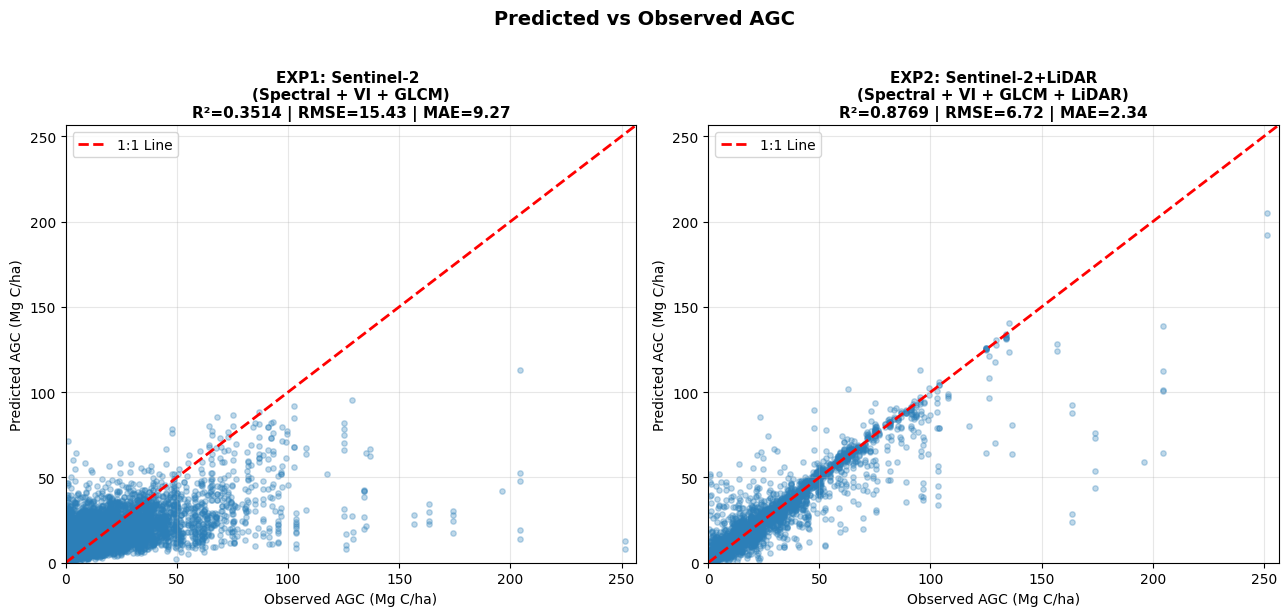

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df_raw = pd.read_csv('/content/mangrove_komodo_multi_band_glcm.csv')
df = df_raw.dropna().copy()
df_results = pd.read_csv('/content/ablation_results_final.csv')

S = [c for c in df.columns if c in ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']]
V = [c for c in df.columns if c in ['NDVI','EVI','SAVI','NDRE','GNDVI','DVI','IRECI']]
L = [c for c in df.columns if c in ['RH25','RH50','RH75','RH95','canopy_height','canopy_ratio']]
G = [c for c in df.columns if any(m in c for m in ['_contrast', '_corr', '_ent', '_asm'])]

y = df['AGC'].values

agc_stats = df_raw['AGC'].agg(
    N='count', Mean='mean', Std='std',
    Min='min', Q25=lambda x: x.quantile(0.25),
    Median='median',
    Q75=lambda x: x.quantile(0.75),
    Max='max', CV=lambda x: (x.std()/x.mean()*100) if x.mean() != 0 else 0
).round(2)

print("=== AGC Descriptive Statistics (Table II) ===")
print(agc_stats)
pd.DataFrame(agc_stats).to_csv('table2_agc_stats.csv')


try:
    r2_s2_full    = df_results[df_results['Configuration'].str.contains('S7: Full S2')]['R2_mean'].values[0]
    r2_lidar_only = df_results[df_results['Configuration'].str.contains('L4: LiDAR')]['R2_mean'].values[0]
    r2_full_all   = df_results[df_results['Configuration'].str.contains('L15: Full')]['R2_mean'].values[0]

    gap_lidar_vs_s2   = r2_lidar_only - r2_s2_full
    lidar_adds_to_s2  = r2_full_all - r2_s2_full
    s2_closes_pct     = (r2_s2_full / r2_lidar_only * 100) if r2_lidar_only > 0 else 0

    print(f"R² Sentinel-2 All Feature\t: {r2_s2_full:.4f}")
    print(f"R² LiDAR Only\t\t\t: {r2_lidar_only:.4f}")
    print(f"R² Sentinel-2 + LiDAR\t\t: {r2_full_all:.4f}")
    print(f"Gap LiDAR vs S2\t\t\t: {gap_lidar_vs_s2:.4f}")
    print(f"S2 vs LiDAR Ratio\t\t: {s2_closes_pct:.1f}%")
except Exception as e:
    print(f"\n[Warning] Gagal mengambil beberapa angka kunci: {e}")

configs_scatter = {
    'EXP1: Sentinel-2 \n(Spectral + VI + GLCM)': S+V+G,
    'EXP2: Sentinel-2+LiDAR\n(Spectral + VI + GLCM + LiDAR)': S+V+G+L
}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
cv = KFold(n_splits=5, shuffle=True, random_state=42)

model_xgb = XGBRegressor(
    n_estimators=100, learning_rate=0.1, max_depth=6,
    colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=0
)

for ax, (label, feats) in zip(axes, configs_scatter.items()):
    X = df[feats].values
    y_pred = cross_val_predict(model_xgb, X, y, cv=cv)

    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    mae = mean_absolute_error(y, y_pred)

    ax.scatter(y, y_pred, alpha=0.3, s=15, color='#2c7fb8', rasterized=True)


    lims = [0, max(y.max(), y_pred.max()) + 5]
    ax.plot(lims, lims, 'r--', linewidth=2, label='1:1 Line')

    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('Observed AGC (Mg C/ha)', fontsize=10)
    ax.set_ylabel('Predicted AGC (Mg C/ha)', fontsize=10)
    ax.set_title(f'{label}\nR²={r2:.4f} | RMSE={rmse:.2f} | MAE={mae:.2f}',
                 fontsize=11, fontweight='bold')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

plt.suptitle('Predicted vs Observed AGC', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figure3_scatter_xgb.png', dpi=300, bbox_inches='tight')
plt.show()

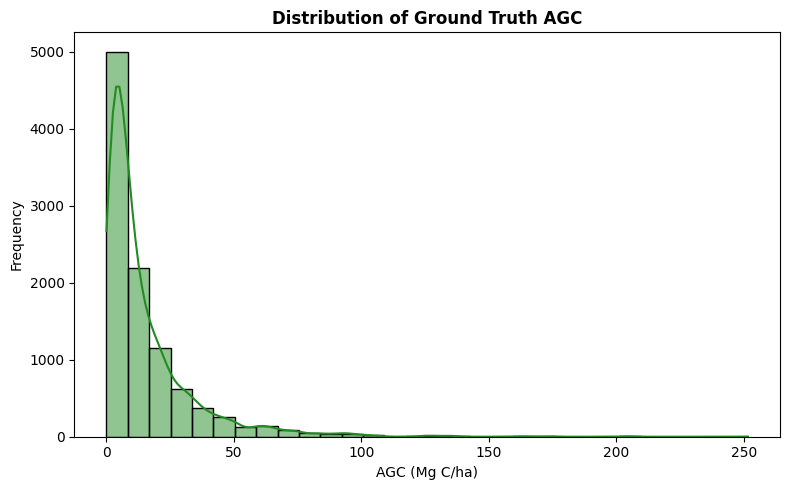

In [ ]:
def plot_distribution(df, target_col='AGC'):
    plt.figure(figsize=(8, 5))
    sns.histplot(df[target_col], kde=True, color='forestgreen', bins=30)
    plt.title(f'Distribution of Ground Truth {target_col}', fontweight='bold')
    plt.xlabel('AGC (Mg C/ha)')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.savefig('distribution_agc.png', dpi=300)
    plt.show()

plot_distribution(df)

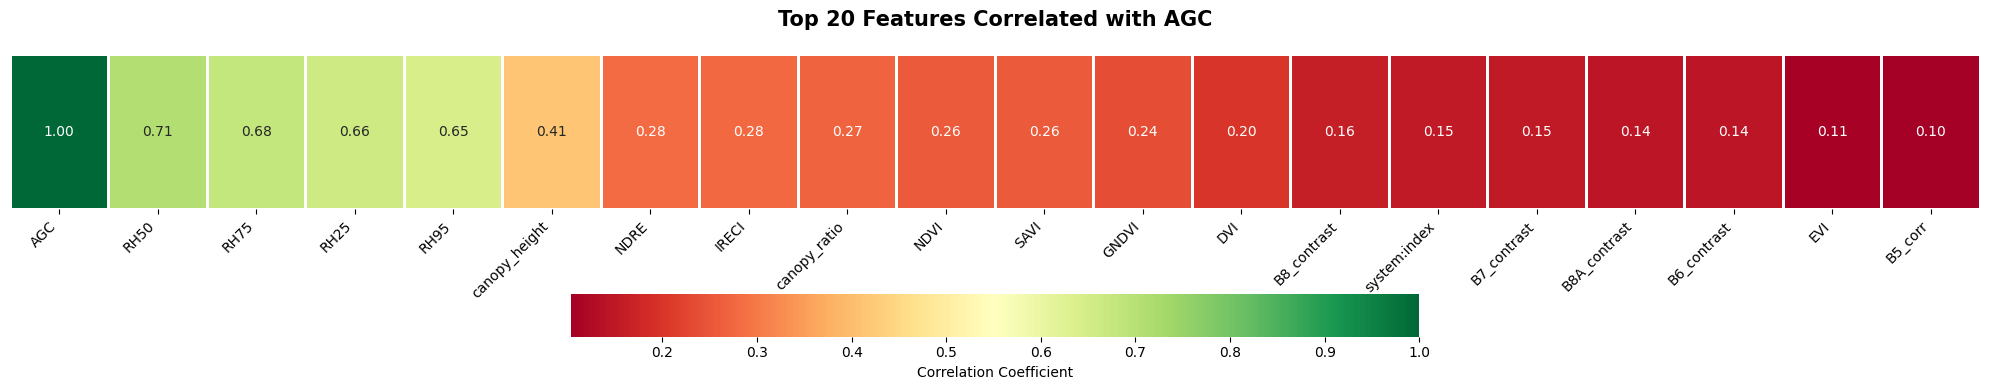

In [ ]:
def plot_correlation_horizontal_v2(df, target_col='AGC', n_features=20):
    df_numeric = df.select_dtypes(include=[np.number])
    correlations = df_numeric.corr()[[target_col]].sort_values(by=target_col, ascending=False)
    top_correlations = correlations.head(n_features).T
    plt.figure(figsize=(20, 4))

    sns.heatmap(top_correlations,
                annot=True,
                cmap='RdYlGn',
                fmt=".2f",
                linewidths=1,
                annot_kws={"size": 10},
                cbar_kws={'label': 'Correlation Coefficient', 'orientation': 'horizontal', 'pad': 0.3})

    plt.title(f'Top {n_features} Features Correlated with {target_col}', fontweight='bold', fontsize=15, pad=20)

    plt.xticks(rotation=45, ha='right')
    plt.yticks([])

    plt.tight_layout()
    plt.show()

plot_correlation_horizontal_v2(df, n_features=20)

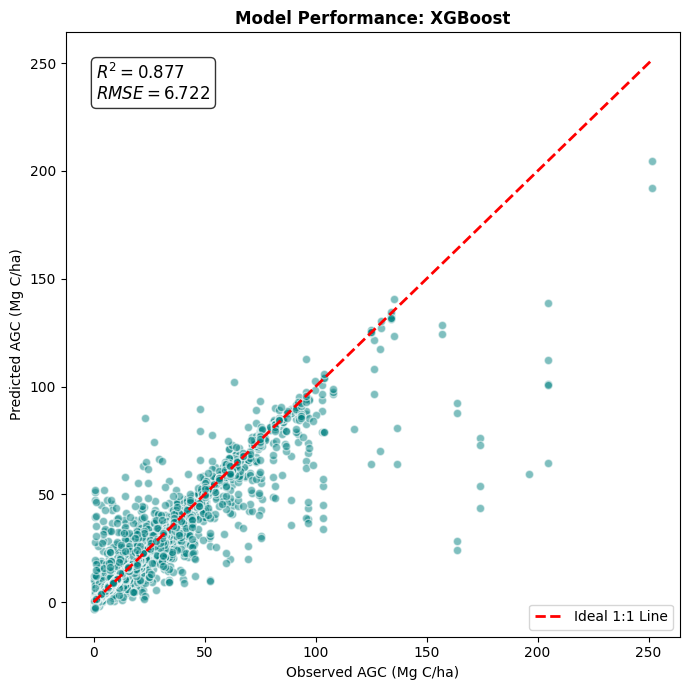

In [ ]:
def plot_regression_results(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    plt.figure(figsize=(7, 7))
    plt.scatter(y_true, y_pred, alpha=0.5, color='teal', edgecolors='white')

    max_val = max(max(y_true), max(y_pred))
    plt.plot([0, max_val], [0, max_val], 'r--', lw=2, label='Ideal 1:1 Line')

    plt.title(f'Model Performance: {model_name}', fontweight='bold')
    plt.xlabel('Observed AGC (Mg C/ha)')
    plt.ylabel('Predicted AGC (Mg C/ha)')

    stats_text = f'$R^2 = {r2:.3f}$\n$RMSE = {rmse:.3f}$'
    plt.gca().text(0.05, 0.95, stats_text, transform=plt.gca().transAxes,
                   fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    plt.legend()
    plt.tight_layout()
    plt.savefig(f'scatter_{model_name.replace(" ", "_")}.png', dpi=300)
    plt.show()

plot_regression_results(y, y_pred, 'XGBoost')

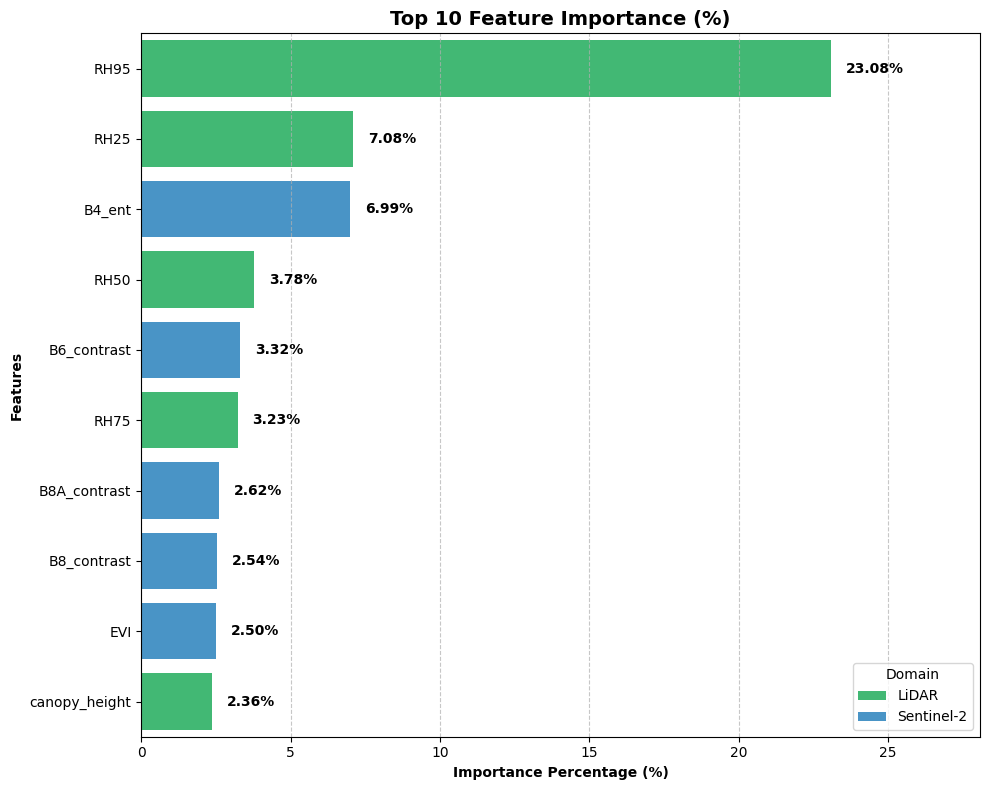

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_importance_pct(importances, feature_names, top_n=15):
    feature_importance = pd.DataFrame({'Feature': feature_names, 'Importance': importances * 100})
    feature_importance = feature_importance.sort_values(by='Importance', ascending=False).head(top_n)
    feature_importance['Domain'] = feature_importance['Feature'].apply(
        lambda x: 'LiDAR' if any(key in x.lower() for key in ['rh', 'canopy']) else 'Sentinel-2'
    )

    plt.figure(figsize=(10, 8))

    ax = sns.barplot(
        x='Importance',
        y='Feature',
        data=feature_importance,
        hue='Domain',
        dodge=False,
        palette={'LiDAR': '#2ecc71', 'Sentinel-2': '#3498db'}
    )

    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.text(width + 0.5, p.get_y() + p.get_height()/2,
                    f'{width:.2f}%',
                    va='center', fontsize=10, fontweight='bold')

    plt.title(f'Top {top_n} Feature Importance (%)', fontweight='bold', fontsize=14)
    plt.xlabel('Importance Percentage (%)', fontweight='bold')
    plt.ylabel('Features', fontweight='bold')
    plt.xlim(0, feature_importance['Importance'].max() + 5)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig('feature_importance_pct.png', dpi=300)
    plt.show()

all_feats = S + V + G + L
feature_names_list = all_feats

X = df[all_feats]
y = df['AGC']

model.fit(X, y)

importances_values = model.feature_importances_

plot_importance_pct(importances_values, feature_names_list, top_n=10)

In [ ]:

from sklearn.inspection import permutation_importance

all_feats = S + V + G + L
X = df[all_feats]
y = df['AGC']

model.fit(X, y)

feature_info = {}
spectral_bands = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']
for b in spectral_bands:
    if b in ['B2', 'B3', 'B4']: t = 'Visible (RGB)'
    elif b in ['B5', 'B6', 'B7', 'B8A']: t = 'Red-Edge'
    elif b == 'B8': t = 'Near-Infrared (NIR)'
    else: t = 'Short-wave Infrared (SWIR)'
    feature_info[b] = {'Domain': 'Sentinel-2', 'Type': f'Spectral {t}'}

vi_list = ['NDVI','EVI','SAVI','NDRE','GNDVI','DVI','IRECI']
for v in vi_list:
    feature_info[v] = {'Domain': 'Sentinel-2', 'Type': 'Vegetation Index'}

for b in target_bands:
    for m in target_metrics:
        col_name = f"{b}_{m}"
        feature_info[col_name] = {'Domain': 'Sentinel-2', 'Type': f'Texture ({m.capitalize()})'}

lidar_metrics = {
    'RH25': 'Height Percentile (Lower)', 'RH50': 'Height Percentile (Median)',
    'RH75': 'Height Percentile (Upper)', 'RH95': 'Height Percentile (Top)',
    'canopy_height': 'Canopy Height Model', 'canopy_ratio': 'Canopy Structure Ratio'
}
for l_col, l_type in lidar_metrics.items():
    feature_info[l_col] = {'Domain': 'LiDAR', 'Type': l_type}

perm_importance = permutation_importance(
    model, X, y, n_repeats=10, random_state=42, scoring='neg_root_mean_squared_error'
)

importance_df = pd.DataFrame({
    'Feature': all_feats,
    'Importance_Raw': model.feature_importances_,
    'Permutation_Delta_RMSE': np.abs(perm_importance.importances_mean)
})

importance_df['Domain'] = importance_df['Feature'].map(lambda x: feature_info.get(x, {}).get('Domain', 'Other'))
importance_df['Type'] = importance_df['Feature'].map(lambda x: feature_info.get(x, {}).get('Type', 'Other'))

importance_df = importance_df.sort_values(by='Importance_Raw', ascending=False).reset_index(drop=True)
importance_df['Importance (%)'] = (importance_df['Importance_Raw'] / importance_df['Importance_Raw'].sum() * 100).round(2)
importance_df['Cumulative (%)'] = importance_df['Importance (%)'].cumsum().round(2)

table_feature_importance = importance_df[[
    'Feature', 'Domain', 'Type', 'Importance (%)', 'Cumulative (%)', 'Permutation_Delta_RMSE'
]]
table_feature_importance.index.name = 'Rank'
table_feature_importance.index += 1

print("\n=== TABLE: FEATURE IMPORTANCE RANKING ===")
print(table_feature_importance.head(15).to_string())


=== TABLE: FEATURE IMPORTANCE RANKING ===
            Feature      Domain                                 Type  Importance (%)  Cumulative (%)  Permutation_Delta_RMSE
Rank                                                                                                                        
1              RH95       LiDAR              Height Percentile (Top)           23.08       23.080000               14.332446
2              RH25       LiDAR            Height Percentile (Lower)            7.08       30.160000                6.995297
3            B4_ent  Sentinel-2                        Texture (Ent)            6.99       37.150002                0.124251
4              RH50       LiDAR           Height Percentile (Median)            3.78       40.930000                5.217319
5       B6_contrast  Sentinel-2                   Texture (Contrast)            3.32       44.250000                2.914341
6              RH75       LiDAR            Height Percentile (Upper)            3.

In [ ]:
!pip install contextily

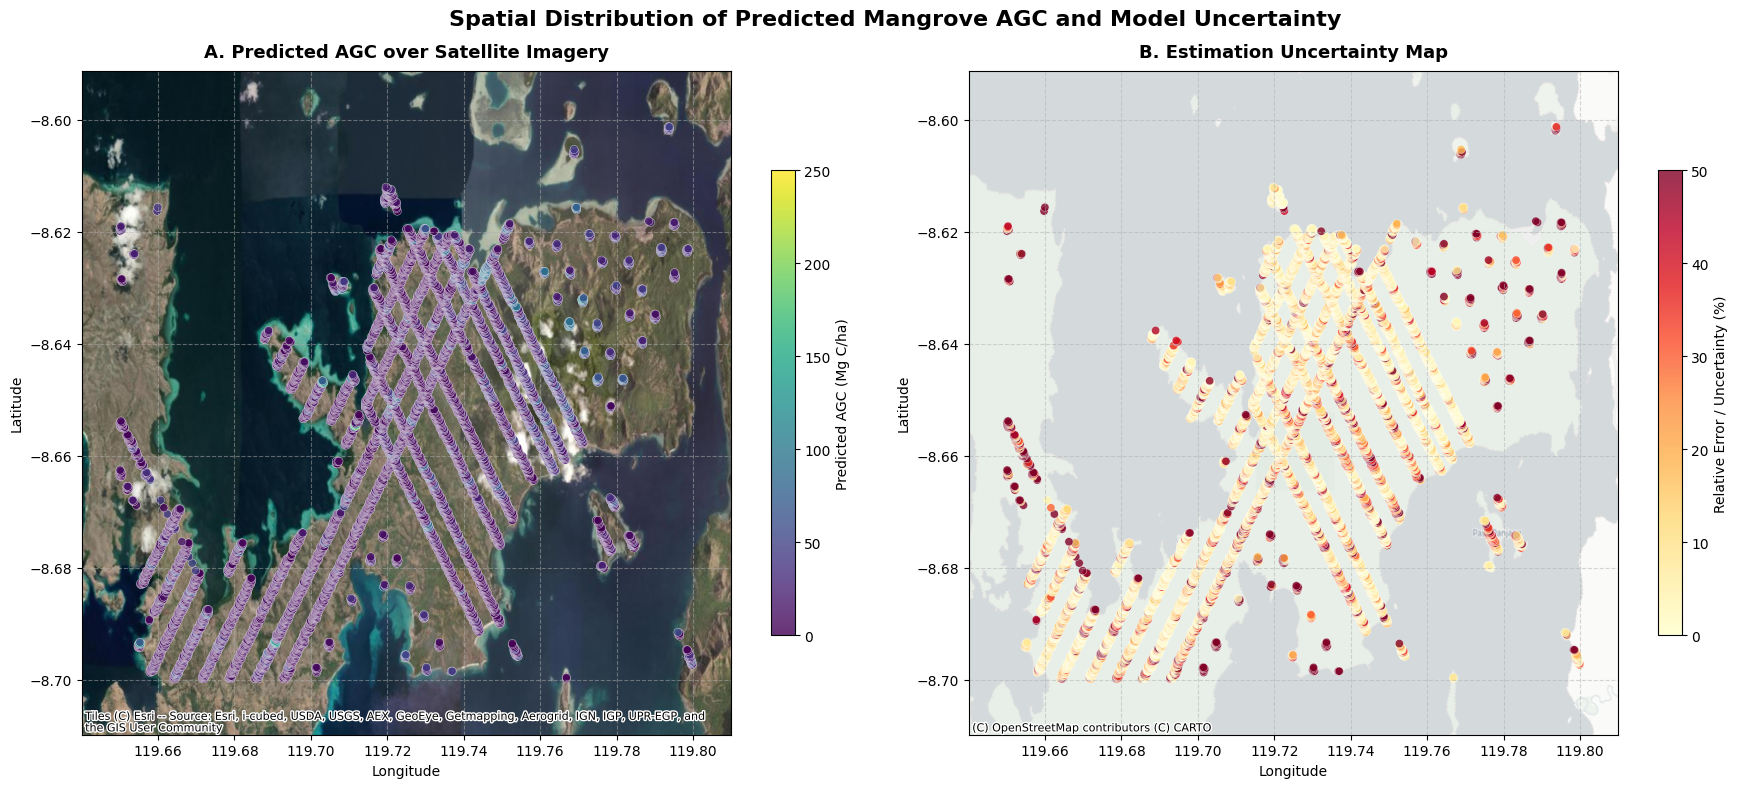

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
import contextily as cx

def extract_coords(df):
    if '.geo' in df.columns:
        coords = df['.geo'].apply(lambda x: json.loads(x)['coordinates'])
        df['lon'] = coords.apply(lambda x: x[0])
        df['lat'] = coords.apply(lambda x: x[1])
    elif 'coordinates' in df.columns:
        df['lon'] = df['coordinates'].apply(lambda x: json.loads(x.replace("'", '"'))[0])
        df['lat'] = df['coordinates'].apply(lambda x: json.loads(x.replace("'", '"'))[1])
    return df

df_with_coords = extract_coords(df_raw.copy())

all_features = S + V + G + L
df_clean = df_with_coords.dropna(subset=all_features + ['AGC']).copy()
df_clean = df_clean.reset_index(drop=True)
X_spatial = df_clean[all_features].values
y_spatial = df_clean['AGC'].values

y_pred_spatial = cross_val_predict(model_xgb, X_spatial, y_spatial, cv=cv, n_jobs=-1)

df_clean['mean_agc'] = y_pred_spatial

df_clean['abs_error'] = np.abs(df_clean['AGC'] - df_clean['mean_agc'])
df_clean['uncertainty_pct'] = (df_clean['abs_error'] / (df_clean['AGC'] + 1)) * 100
df_clean['uncertainty_clipped'] = np.clip(df_clean['uncertainty_pct'], 0, 50)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

sc1 = ax1.scatter(df_clean['lon'], df_clean['lat'], c=df_clean['mean_agc'],
                  cmap='viridis', s=35, alpha=0.8, vmin=0, vmax=250, edgecolor='white', linewidth=0.3)

cx.add_basemap(ax1, crs='EPSG:4326', source=cx.providers.Esri.WorldImagery)
ax1.set_title('A. Predicted AGC over Satellite Imagery', fontsize=13, fontweight='bold', pad=10)
fig.colorbar(sc1, ax=ax1, label='Predicted AGC (Mg C/ha)', shrink=0.7)


sc2 = ax2.scatter(df_clean['lon'], df_clean['lat'], c=df_clean['uncertainty_clipped'],
                  cmap='YlOrRd', s=35, alpha=0.8, vmin=0, vmax=50, edgecolor='white', linewidth=0.3)
cx.add_basemap(ax2, crs='EPSG:4326', source=cx.providers.CartoDB.Positron)
ax2.set_title('B. Estimation Uncertainty Map', fontsize=13, fontweight='bold', pad=10)
fig.colorbar(sc2, ax=ax2, label='Relative Error / Uncertainty (%)', shrink=0.7)


for ax in [ax1, ax2]:
    ax.set_xlabel('Longitude', fontsize=10)
    ax.set_ylabel('Latitude', fontsize=10)
    ax.set_xlim(df_clean['lon'].min() - 0.01, df_clean['lon'].max() + 0.01)
    ax.set_ylim(df_clean['lat'].min() - 0.01, df_clean['lat'].max() + 0.01)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Spatial Distribution of Predicted Mangrove AGC and Model Uncertainty',
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('figure5_spatial_with_basemap_fixed.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (make_scorer, r2_score,
                             mean_squared_error, mean_absolute_error)


df = pd.read_csv('/content/mangrove_komodo_multi_band_glcm.csv')
df = df.dropna()

target_bands = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']
target_metrics = ['contrast', 'corr', 'ent', 'asm']


glcm_columns = []
for b in target_bands:
    for m in target_metrics:
        col_name = f"{b}_{m}"
        if col_name in df.columns:
            glcm_columns.append(col_name)



feature_groups = {
    'Spectral': [c for c in df.columns if c in
        ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']],

    'VI': [c for c in df.columns if c in
        ['NDVI','EVI','SAVI','NDRE','GNDVI','DVI','IRECI']],

    'GLCM': glcm_columns,

    'LiDAR': [c for c in df.columns if c in
        ['RH25','RH50','RH75','RH95',
         'canopy_height','canopy_ratio']]
}

for k, v in feature_groups.items():
    print(f"{k}: {v}")

S = feature_groups['Spectral']
V = feature_groups['VI']
G = feature_groups['GLCM']
L = feature_groups['LiDAR']

feats_full = S + V + G + L
feats_full = [f for f in feats_full if f in df.columns]

ablation_s2 = {
    'S1: Spectral': S,
    'S2: VI': V,
    'S3: GLCM': G,
    'S4: Spectral+VI': S+V,
    'S5: Spectral+GLCM': S+G,
    'S6: VI+GLCM': V+G,
    'S7: Full S2': S+V+G,
}


ablation_s2_lidar = {
    'L1: Spectral': S,
    'L2: VI': V,
    'L3: GLCM': G,
    'L4: LiDAR': L,
    'L5: Spectral+VI': S+V,
    'L6: Spectral+GLCM': S+G,
    'L7: Spectral+LiDAR': S+L,
    'L8: VI+GLCM': V+G,
    'L9: VI+LiDAR': V+L,
    'L10: GLCM+LiDAR': G+L,
    'L11: Spectral+VI+GLCM': S+V+G,
    'L12: Spectral+VI+LiDAR': S+V+L,
    'L13: Spectral+GLCM+LiDAR': S+G+L,
    'L14: VI+GLCM+LiDAR': V+G+L,
    'L15: Full (S+VI+GLCM+LiDAR)': S+V+G+L,
}


def rmse_scorer(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

scorers = {
    'r2': make_scorer(r2_score),
    'rmse': make_scorer(rmse_scorer),
    'mae': make_scorer(mean_absolute_error)
}


model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

X_all = df[feats_full].values
y_all = df['AGC'].values
model.fit(X_all, y_all)

X_contoh = df[feats_full].head(5).values
y_true = df['AGC'].head(5).values
y_pred = model.predict(X_contoh)
n_contoh = len(y_true)
y_mean = np.mean(y_true)

error = y_true - y_pred
squared_error = error ** 2
mse = np.sum(squared_error) / n_contoh
rmse = np.sqrt(mse)

ssr = np.sum(squared_error)
sst = np.sum((y_true - y_mean) ** 2)
r2 = 1 - (ssr / sst)

print("\n" + "="*60)
print("CONTOH PERHITUNGAN UNTUK DOSEN (MASUKKAN KE PAPER)")
print("="*60)

df_ilustrasi = pd.DataFrame({
    'Reference AGC (y)': np.round(y_true, 2),
    'Predicted AGC (y_hat)': np.round(y_pred, 2),
    'Error (y - y_hat)': np.round(error, 2),
    'Squared Error': np.round(squared_error, 2)
})

print("\nTabel Ilustrasi 5 Data Pertama:")
print(df_ilustrasi.to_markdown(index=False))
print("\n")

print("--- HASIL AKHIR METRIK EVALUASI (5 SAMPEL) ---")
print(f"Rata-rata Reference (y_bar) : {y_mean:.2f} Mg C/ha")
print(f"Hasil Akhir Hitungan RMSE   : {rmse:.2f} Mg C/ha")
print(f"Hasil Akhir Hitungan R²     : {r2:.4f}")
print("="*60)

Spectral: ['B11', 'B12', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A']
VI: ['DVI', 'EVI', 'GNDVI', 'IRECI', 'NDRE', 'NDVI', 'SAVI']
GLCM: ['B2_contrast', 'B2_corr', 'B2_ent', 'B2_asm', 'B3_contrast', 'B3_corr', 'B3_ent', 'B3_asm', 'B4_contrast', 'B4_corr', 'B4_ent', 'B4_asm', 'B5_contrast', 'B5_corr', 'B5_ent', 'B5_asm', 'B6_contrast', 'B6_corr', 'B6_ent', 'B6_asm', 'B7_contrast', 'B7_corr', 'B7_ent', 'B7_asm', 'B8_contrast', 'B8_corr', 'B8_ent', 'B8_asm', 'B8A_contrast', 'B8A_corr', 'B8A_ent', 'B8A_asm', 'B11_contrast', 'B11_corr', 'B11_ent', 'B11_asm', 'B12_contrast', 'B12_corr', 'B12_ent', 'B12_asm']
LiDAR: ['RH25', 'RH50', 'RH75', 'RH95', 'canopy_height', 'canopy_ratio']

CONTOH PERHITUNGAN UNTUK DOSEN (MASUKKAN KE PAPER)

Tabel Ilustrasi 5 Data Pertama:
|   Reference AGC (y) |   Predicted AGC (y_hat) |   Error (y - y_hat) |   Squared Error |
|--------------------:|------------------------:|--------------------:|----------------:|
|                3.03 |                    3.58 